## **Setup and data loading**

In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.grid"] = True

print(pd.__version__, np.__version__)

2.2.3 2.4.6


In [66]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [67]:
DATA_PATH = "/content/drive/MyDrive/world_economic_indicators/"

In [68]:
import os
os.listdir(DATA_PATH)

['WorldBank.xlsx',
 'HDI.csv',
 'world_indicators_data_dictionary.csv',
 'wb_clean.csv',
 'hdi_panel_clean.csv',
 'master_1990_2018.csv']

In [69]:
encoding = "latin-1"
df1 = pd.read_excel(DATA_PATH + "WorldBank.xlsx")
df2 = pd.read_csv(DATA_PATH + "HDI.csv", encoding=encoding)
df3 = pd.read_csv(DATA_PATH + "world_indicators_data_dictionary.csv", encoding=encoding)

In [70]:
for name, df in {"df1": df1, "df2": df2, "df3": df3}.items():
    print(f"\n===== {name} =====")
    print("Shape:", df.shape)
    display(df.head())
    df.info()
    print("Missing values:\n", df.isna().sum().sort_values(ascending=False).head(10))
    print("Duplicate rows:", df.duplicated().sum())


===== df1 =====
Shape: (12449, 15)


,Country Name,Country Code,Region,IncomeGroup,Year,"Birth rate, crude (per 1,000 people)","Death rate, crude (per 1,000 people)",Electric power consumption (kWh per capita),GDP (USD),GDP per capita (USD),Individuals using the Internet (% of population),"Infant mortality rate (per 1,000 live births)",Life expectancy at birth (years),Population density (people per sq. km of land area),Unemployment (% of total labor force) (modeled ILO estimate)
0,Afghanistan,AFG,South Asia,Low income,2018,NaN,NaN,NaN,"19,363,000,000.00",520.90,NaN,47.90,NaN,56.94,1.54
1,Afghanistan,AFG,South Asia,Low income,2017,33.21,6.58,NaN,"20,191,800,000.00",556.30,13.50,49.50,64.13,55.60,1.56
2,Afghanistan,AFG,South Asia,Low income,2016,33.98,6.74,NaN,"19,362,600,000.00",547.23,11.20,51.20,63.76,54.20,1.63
3,Afghanistan,AFG,South Asia,Low income,2015,34.81,6.93,NaN,"19,907,100,000.00",578.47,8.26,53.10,63.38,52.71,1.68
4,Afghanistan,AFG,South Asia,Low income,2014,35.71,7.14,NaN,"20,484,900,000.00",613.86,7.00,55.10,62.97,51.11,1.74


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12449 entries, 0 to 12448
Data columns (total 15 columns):
 #   Column                                                        Non-Null Count  Dtype  
---  ------                                                        --------------  -----  
 0   Country Name                                                  12449 non-null  object 
 1   Country Code                                                  12449 non-null  object 
 2   Region                                                        12449 non-null  object 
 3   IncomeGroup                                                   12449 non-null  object 
 4   Year                                                          12449 non-null  int64  
 5   Birth rate, crude (per 1,000 people)                          11440 non-null  float64
 6   Death rate, crude (per 1,000 people)                          11416 non-null  float64
 7   Electric power consumption (kWh per capita)                   5848 

,iso3,country,hdicode,region,hdi_rank_2021,hdi_1990,hdi_1991,hdi_1992,hdi_1993,hdi_1994,hdi_1995,hdi_1996,hdi_1997,hdi_1998,hdi_1999,hdi_2000,hdi_2001,hdi_2002,hdi_2003,hdi_2004,hdi_2005,hdi_2006,hdi_2007,hdi_2008,hdi_2009,hdi_2010,hdi_2011,hdi_2012,hdi_2013,hdi_2014,hdi_2015,hdi_2016,hdi_2017,hdi_2018,hdi_2019,hdi_2020,hdi_2021,le_1990,le_1991,le_1992,le_1993,le_1994,le_1995,le_1996,le_1997,le_1998,le_1999,le_2000,le_2001,le_2002,le_2003,le_2004,le_2005,le_2006,le_2007,le_2008,le_2009,le_2010,le_2011,le_2012,le_2013,le_2014,le_2015,le_2016,le_2017,le_2018,le_2019,le_2020,le_2021,eys_1990,eys_1991,eys_1992,eys_1993,eys_1994,eys_1995,eys_1996,eys_1997,eys_1998,eys_1999,eys_2000,eys_2001,eys_2002,eys_2003,eys_2004,eys_2005,eys_2006,eys_2007,eys_2008,eys_2009,eys_2010,eys_2011,eys_2012,eys_2013,eys_2014,eys_2015,eys_2016,eys_2017,eys_2018,eys_2019,eys_2020,eys_2021,mys_1990,mys_1991,mys_1992,mys_1993,mys_1994,mys_1995,mys_1996,mys_1997,mys_1998,mys_1999,mys_2000,mys_2001,mys_2002,mys_2003,mys_2004,mys_2005,mys_2006,mys_2007,mys_2008,mys_2009,mys_2010,mys_2011,mys_2012,mys_2013,mys_2014,mys_2015,mys_2016,mys_2017,mys_2018,mys_2019,mys_2020,mys_2021,gnipc_1990,gnipc_1991,gnipc_1992,gnipc_1993,gnipc_1994,gnipc_1995,gnipc_1996,gnipc_1997,gnipc_1998,gnipc_1999,gnipc_2000,gnipc_2001,gnipc_2002,gnipc_2003,gnipc_2004,gnipc_2005,gnipc_2006,gnipc_2007,gnipc_2008,gnipc_2009,gnipc_2010,gnipc_2011,gnipc_2012,gnipc_2013,gnipc_2014,gnipc_2015,gnipc_2016,gnipc_2017,gnipc_2018,gnipc_2019,gnipc_2020,gnipc_2021,gdi_group_2021,gdi_1990,gdi_1991,gdi_1992,gdi_1993,gdi_1994,gdi_1995,gdi_1996,gdi_1997,gdi_1998,gdi_1999,gdi_2000,gdi_2001,gdi_2002,gdi_2003,gdi_2004,gdi_2005,gdi_2006,gdi_2007,gdi_2008,gdi_2009,gdi_2010,gdi_2011,gdi_2012,gdi_2013,gdi_2014,gdi_2015,gdi_2016,gdi_2017,gdi_2018,gdi_2019,gdi_2020,gdi_2021,hdi_f_1990,hdi_f_1991,hdi_f_1992,hdi_f_1993,hdi_f_1994,hdi_f_1995,hdi_f_1996,hdi_f_1997,hdi_f_1998,hdi_f_1999,hdi_f_2000,hdi_f_2001,hdi_f_2002,hdi_f_2003,hdi_f_2004,hdi_f_2005,hdi_f_2006,hdi_f_2007,hdi_f_2008,hdi_f_2009,hdi_f_2010,hdi_f_2011,hdi_f_2012,hdi_f_2013,hdi_f_2014,hdi_f_2015,hdi_f_2016,hdi_f_2017,hdi_f_2018,hdi_f_2019,hdi_f_2020,hdi_f_2021,le_f_1990,le_f_1991,le_f_1992,le_f_1993,le_f_1994,le_f_1995,le_f_1996,le_f_1997,le_f_1998,le_f_1999,le_f_2000,le_f_2001,le_f_2002,le_f_2003,le_f_2004,le_f_2005,le_f_2006,le_f_2007,le_f_2008,le_f_2009,le_f_2010,le_f_2011,le_f_2012,le_f_2013,le_f_2014,le_f_2015,le_f_2016,le_f_2017,le_f_2018,le_f_2019,le_f_2020,le_f_2021,eys_f_1990,eys_f_1991,eys_f_1992,eys_f_1993,eys_f_1994,eys_f_1995,eys_f_1996,eys_f_1997,eys_f_1998,eys_f_1999,eys_f_2000,eys_f_2001,eys_f_2002,eys_f_2003,eys_f_2004,eys_f_2005,eys_f_2006,eys_f_2007,eys_f_2008,eys_f_2009,eys_f_2010,eys_f_2011,eys_f_2012,eys_f_2013,eys_f_2014,eys_f_2015,eys_f_2016,eys_f_2017,eys_f_2018,eys_f_2019,eys_f_2020,eys_f_2021,mys_f_1990,mys_f_1991,mys_f_1992,mys_f_1993,mys_f_1994,mys_f_1995,mys_f_1996,mys_f_1997,mys_f_1998,mys_f_1999,mys_f_2000,mys_f_2001,mys_f_2002,mys_f_2003,mys_f_2004,mys_f_2005,mys_f_2006,mys_f_2007,mys_f_2008,mys_f_2009,mys_f_2010,mys_f_2011,mys_f_2012,mys_f_2013,mys_f_2014,mys_f_2015,mys_f_2016,mys_f_2017,mys_f_2018,mys_f_2019,mys_f_2020,mys_f_2021,gni_pc_f_1990,gni_pc_f_1991,gni_pc_f_1992,gni_pc_f_1993,gni_pc_f_1994,gni_pc_f_1995,gni_pc_f_1996,gni_pc_f_1997,gni_pc_f_1998,gni_pc_f_1999,gni_pc_f_2000,gni_pc_f_2001,gni_pc_f_2002,gni_pc_f_2003,gni_pc_f_2004,gni_pc_f_2005,gni_pc_f_2006,gni_pc_f_2007,gni_pc_f_2008,gni_pc_f_2009,gni_pc_f_2010,gni_pc_f_2011,gni_pc_f_2012,gni_pc_f_2013,gni_pc_f_2014,gni_pc_f_2015,gni_pc_f_2016,gni_pc_f_2017,gni_pc_f_2018,gni_pc_f_2019,gni_pc_f_2020,gni_pc_f_2021,hdi_m_1990,hdi_m_1991,hdi_m_1992,hdi_m_1993,hdi_m_1994,hdi_m_1995,hdi_m_1996,hdi_m_1997,hdi_m_1998,hdi_m_1999,hdi_m_2000,hdi_m_2001,hdi_m_2002,hdi_m_2003,hdi_m_2004,hdi_m_2005,hdi_m_2006,hdi_m_2007,hdi_m_2008,hdi_m_2009,hdi_m_2010,hdi_m_2011,hdi_m_2012,hdi_m_2013,hdi_m_2014,hdi_m_2015,hdi_m_2016,hdi_m_2017,hdi_m_2018,hdi_m_2019,hdi_m_2020,hdi_m_2021,le_m_1

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 206 entries, 0 to 205
Columns: 1008 entries, iso3 to mf_2021
dtypes: float64(1004), object(4)
memory usage: 1.6+ MB
Missing values:
 gdi_1992      87
hdi_f_1990    87
hdi_f_1991    87
hdi_f_1992    87
hdi_m_1990    87
hdi_m_1992    87
gdi_1991      87
gdi_1990      87
hdi_m_1991    87
hdi_f_1993    86
dtype: int64
Duplicate rows: 0

===== df3 =====
Shape: (58, 3)


,Table,Field,Description
0,WorldBank,Country Name,The name of the country
1,WorldBank,Country Code,The three letter code representing the country
2,WorldBank,Region,The World Bank region of the country
3,WorldBank,IncomeGroup,The World Bank Income Group of the country
4,WorldBank,Year,The Year in which the statistics were recorded


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58 entries, 0 to 57
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Table        58 non-null     object
 1   Field        58 non-null     object
 2   Description  58 non-null     object
dtypes: object(3)
memory usage: 1.5+ KB
Missing values:
 Table          0
Field          0
Description    0
dtype: int64
Duplicate rows: 0


## **Data cleaning**

**Step 1: Keep the raw data and rename columns**

In [71]:
wb_raw = df1
wb = wb_raw.copy()

wb = wb.rename(columns={
    'Country Name': 'country',
    'Country Code': 'country_code',
    'Region': 'region',
    'IncomeGroup': 'income_group',
    'Year': 'year',
    'Birth rate, crude (per 1,000 people)': 'birth_rate',
    'Death rate, crude (per 1,000 people)': 'death_rate',
    'Electric power consumption (kWh per capita)': 'electricity_kwh_pc',
    'GDP (USD)': 'gdp_usd',
    'GDP per capita (USD)': 'gdp_per_capita',
    'Individuals using the Internet (% of population)': 'internet_pct',
    'Infant mortality rate (per 1,000 live births)': 'infant_mortality',
    'Life expectancy at birth (years)': 'life_expectancy',
    'Population density (people per sq. km of land area)': 'pop_density',
    'Unemployment (% of total labor force) (modeled ILO estimate)': 'unemployment_pct',
})

indicators = ['birth_rate', 'death_rate', 'electricity_kwh_pc', 'gdp_usd',
              'gdp_per_capita', 'internet_pct', 'infant_mortality',
              'life_expectancy', 'pop_density', 'unemployment_pct']

# Strip stray whitespace in text columns
for col in ['country', 'country_code', 'region', 'income_group']:
    wb[col] = wb[col].str.strip()

**Step 2: Structural checks**

In [72]:
print("Shape:", wb.shape)
print("Years:", wb['year'].min(), "-", wb['year'].max())
print("Countries:", wb['country_code'].nunique())
print("Duplicate country-year rows:", wb.duplicated(['country_code', 'year']).sum())
print("Rows per country (should be 59 for all):")
print(wb.groupby('country_code').size().value_counts())

# Region / income group should be constant within a country
print("\nMax distinct values per country:")
print(wb.groupby('country_code')[['region', 'income_group']].nunique().max())

# Countries per category
countries = wb.drop_duplicates('country_code')
print("\n", countries['region'].value_counts())
print("\n", countries['income_group'].value_counts())

Shape: (12449, 15)
Years: 1960 - 2018
Countries: 211
Duplicate country-year rows: 0
Rows per country (should be 59 for all):
59    211
Name: count, dtype: int64

Max distinct values per country:
region          1
income_group    1
dtype: int64

 region
Europe & Central Asia         56
Sub-Saharan Africa            48
Latin America & Caribbean     41
East Asia & Pacific           34
Middle East & North Africa    21
South Asia                     8
North America                  3
Name: count, dtype: int64

 income_group
Upper middle income     53
Lower middle income     48
High income: nonOECD    47
High income: OECD       32
Low income              31
Name: count, dtype: int64


In [73]:
print(sorted(wb['country'].unique()))

['Afghanistan', 'Albania', 'Algeria', 'American Samoa', 'Andorra', 'Angola', 'Antigua and Barbuda', 'Argentina', 'Armenia', 'Aruba', 'Australia', 'Austria', 'Azerbaijan', 'Bahamas, The', 'Bahrain', 'Bangladesh', 'Barbados', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bermuda', 'Bhutan', 'Bolivia', 'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Brunei Darussalam', 'Bulgaria', 'Burkina Faso', 'Burundi', 'Cabo Verde', 'Cambodia', 'Cameroon', 'Canada', 'Cayman Islands', 'Central African Republic', 'Chad', 'Channel Islands', 'Chile', 'China', 'Colombia', 'Comoros', 'Congo, Dem. Rep.', 'Congo, Rep.', 'Costa Rica', "Cote d'Ivoire", 'Croatia', 'Cuba', 'Curacao', 'Cyprus', 'Czech Republic', 'Denmark', 'Djibouti', 'Dominica', 'Dominican Republic', 'Ecuador', 'Egypt, Arab Rep.', 'El Salvador', 'Equatorial Guinea', 'Eritrea', 'Estonia', 'Eswatini', 'Ethiopia', 'Faroe Islands', 'Fiji', 'Finland', 'France', 'French Polynesia', 'Gabon', 'Gambia, The', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Greenla

**Step 3: Missing values**

In [74]:
missing = (wb[indicators].isna().mean() * 100).round(1).sort_values(ascending=False)
print(missing)

internet_pct         59.30
unemployment_pct     58.20
electricity_kwh_pc   53.00
gdp_usd              23.10
gdp_per_capita       23.10
infant_mortality     19.80
life_expectancy      10.20
death_rate            8.30
birth_rate            8.10
pop_density           4.90
dtype: float64


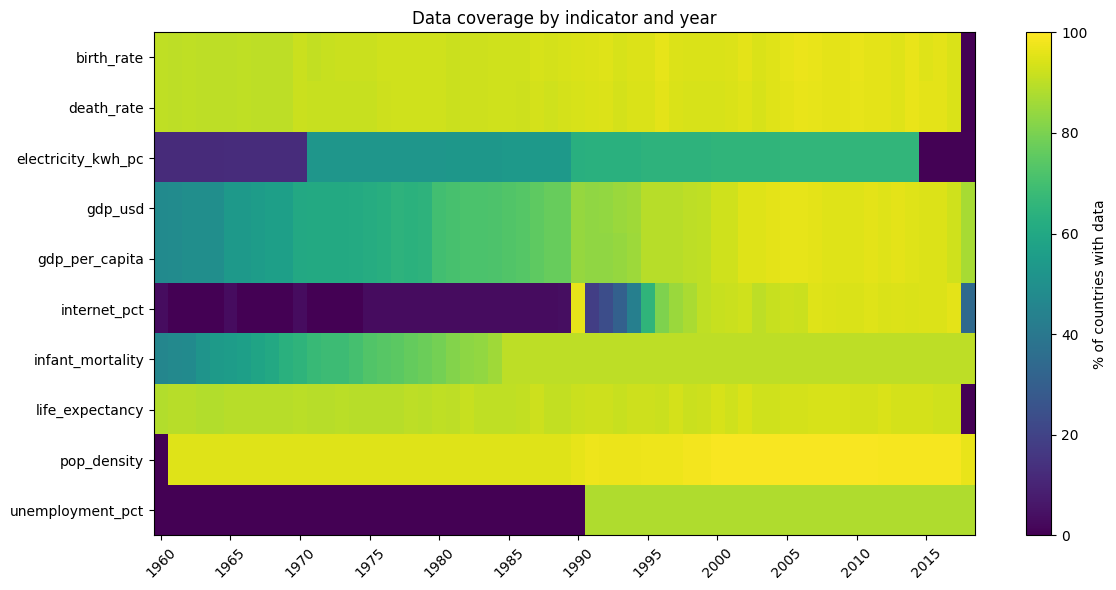

In [75]:
n_countries = wb['country_code'].nunique()
coverage = wb.groupby('year')[indicators].count() / n_countries * 100

fig, ax = plt.subplots(figsize=(12, 6))
im = ax.imshow(coverage.T, aspect='auto', cmap='viridis', vmin=0, vmax=100)
ax.set_xticks(range(0, len(coverage.index), 5))
ax.set_xticklabels(coverage.index[::5], rotation=45)
ax.set_yticks(range(len(indicators)))
ax.set_yticklabels(indicators)
ax.grid(False)
plt.colorbar(im, label='% of countries with data')
ax.set_title('Data coverage by indicator and year')
plt.tight_layout()
plt.show()

**Step 4: Sanity-check values**

In [76]:
print(wb[indicators].describe().T)

checks = {
    'internet_pct > 100': (wb['internet_pct'] > 100).sum(),
    'life_expectancy outside 15-90': ((wb['life_expectancy'] < 15) | (wb['life_expectancy'] > 90)).sum(),
    'gdp_usd <= 0': (wb['gdp_usd'] <= 0).sum(),
    'gdp_per_capita <= 0': (wb['gdp_per_capita'] <= 0).sum(),
    'any negative indicator': (wb[indicators] < 0).sum().sum(),
}
for k, v in checks.items():
    print(f"{k}: {v}")

                       count               mean                std  \
birth_rate         11,440.00              28.64              13.13   
death_rate         11,416.00              10.59               5.49   
electricity_kwh_pc  5,848.00           3,175.29           4,467.14   
gdp_usd             9,578.00 170,073,972,643.43 897,986,611,233.97   
gdp_per_capita      9,575.00           8,231.81          16,173.54   
internet_pct        5,064.00              23.33              28.32   
infant_mortality    9,984.00              51.70              46.13   
life_expectancy    11,176.00              64.04              11.49   
pop_density        11,845.00             318.86           1,593.41   
unemployment_pct    5,208.00               8.30               6.29   

                            min              25%              50%  \
birth_rate                 6.90            16.60            27.55   
death_rate                 1.13             6.86             9.20   
electricity_kwh_pc    

**Step 5: Derive population**

In [77]:
wb['population_est'] = wb['gdp_usd'] / wb['gdp_per_capita']

# Sanity check against known values (India 2018 is roughly 1.35 billion)
print(wb.query("country_code == 'IND' and year == 2018")[['country', 'population_est']])
print(wb.query("country_code == 'USA' and year == 2018")[['country', 'population_est']])

     country   population_est
5133   India 1,354,442,123.65
             country  population_est
11800  United States  327,261,697.61


**Step 6: Clean the HDI table**

In [78]:
pd.set_option("display.max_colwidth", None)
data_dict = df3
data_dict[data_dict['Table'] != 'WorldBank']

,Table,Field,Description
15,hdi,iso3,The three letter code representing the country
16,hdi,country,The name of the country
17,hdi,hdicode,The hdi grouping from the UN
18,hdi,region,The UNDP development regions
19,hdi,hdi_rank_2021,The country's HDI rank in 2021
20,hdi,hdi_xxxx,The country's HDI in year xxxx
21,hdi,le_xxxx,The country's life expectancy in year xxxx
22,hdi,eys_xxxx,The country's expeected years of schooling
23,hdi,mys_xxxx,The country's mean years of schooling
24,hdi,gnipc_xxxx,The gross national income per capita in 2017 PPP dollars


In [79]:
import re

hdi_raw = df2
hdi = hdi_raw.copy()

id_cols = hdi.select_dtypes(include='object').columns.tolist()
print("ID columns:", id_cols)   # expect something like iso3, country, hdicode, region

year_cols = [c for c in hdi.columns if re.search(r'_\d{4}$', c)]
prefixes = sorted({re.sub(r'_\d{4}$', '', c) for c in year_cols})
print(len(prefixes), "indicators:", prefixes)

# Is there a population column?
print([p for p in prefixes if 'pop' in p])

ID columns: ['iso3', 'country', 'hdicode', 'region']
39 indicators: ['abr', 'co2_prod', 'coef_ineq', 'diff_hdi_phdi', 'eys', 'eys_f', 'eys_m', 'gdi', 'gdi_group', 'gii', 'gii_rank', 'gni_pc_f', 'gni_pc_m', 'gnipc', 'hdi', 'hdi_f', 'hdi_m', 'hdi_rank', 'ihdi', 'ineq_edu', 'ineq_inc', 'ineq_le', 'le', 'le_f', 'le_m', 'lfpr_f', 'lfpr_m', 'loss', 'mf', 'mmr', 'mys', 'mys_f', 'mys_m', 'phdi', 'pr_f', 'pr_m', 'rankdiff_hdi_phdi', 'se_f', 'se_m']
[]


In [80]:
print(hdi[~hdi['iso3'].str.fullmatch(r'[A-Z]{3}')][['iso3', 'country']])

          iso3                          country
195   ZZA.VHHD      Very high human development
196    ZZB.HHD           High human development
197    ZZC.MHD         Medium human development
198    ZZD.LHD            Low human development
199     ZZE.AS                      Arab States
200    ZZF.EAP        East Asia and the Pacific
201    ZZG.ECA          Europe and Central Asia
202    ZZH.LAC  Latin America and the Caribbean
203     ZZI.SA                       South Asia
204    ZZJ.SSA               Sub-Saharan Africa
205  ZZK.WORLD                            World


In [81]:
hdi = hdi[hdi['iso3'].str.fullmatch(r'[A-Z]{3}')].copy()

hdi_meta = hdi[id_cols].drop_duplicates('iso3')   # keep UN region labels for reference

hdi_long = hdi.melt(id_vars=id_cols, value_vars=year_cols,
                    var_name='col', value_name='value')
hdi_long[['indicator', 'year']] = hdi_long['col'].str.extract(r'^(.*)_(\d{4})$')
hdi_long['year'] = hdi_long['year'].astype(int)

# One row per country-year, one column per indicator
hdi_panel = (hdi_long
             .pivot_table(index=['iso3', 'year'], columns='indicator', values='value')
             .reset_index())
hdi_panel.columns.name = None
hdi_panel = hdi_panel.drop(columns=['hdi_rank'], errors='ignore')  # rank exists for 2021 only

print(hdi_panel.shape)
print(hdi_panel[['iso3', 'year', 'hdi']].head())

(6240, 40)
  iso3  year  hdi
0  AFG  1990 0.27
1  AFG  1991 0.28
2  AFG  1992 0.29
3  AFG  1993 0.30
4  AFG  1994 0.29


**Step 7: Check that the two tables line up, then merge**

In [82]:
wb_codes, hdi_codes = set(wb['country_code']), set(hdi_panel['iso3'])
print("In World Bank but not HDI:", sorted(wb_codes - hdi_codes))
print("In HDI but not World Bank:", sorted(hdi_codes - wb_codes))

In World Bank but not HDI: ['ABW', 'ASM', 'BMU', 'CHI', 'CUW', 'CYM', 'FRO', 'GRL', 'GUM', 'IMN', 'MAC', 'MAF', 'MNP', 'NCL', 'PRI', 'PYF', 'SXM', 'TCA', 'VIR']
In HDI but not World Bank: ['FSM', 'LAO', 'NRU']


In [83]:
master = wb.merge(hdi_panel, left_on=['country_code', 'year'],
                  right_on=['iso3', 'year'], how='left')

print(master.shape)  # row count must still equal wb's 12,449
print("Rows with HDI data:", master['hdi'].notna().sum())

(12449, 55)
Rows with HDI data: 4950


**Step 8: Save the cleaned data**

In [84]:
wb.to_csv(DATA_PATH + "wb_clean.csv", index=False)
hdi_panel.to_csv(DATA_PATH + "hdi_panel_clean.csv", index=False)
master.to_csv(DATA_PATH + "master_1990_2018.csv", index=False)

**simplify income groups and find the best years**

In [85]:
# 1. Simplified income groups for Q4
income_map = {
    'High income: OECD': 'High income',
    'High income: nonOECD': 'High income',
    'Upper middle income': 'Upper middle income',
    'Lower middle income': 'Lower middle income',
    'Low income': 'Low income'
}
wb['income_simple'] = wb['income_group'].map(income_map)
wb['income_simple'] = pd.Categorical(
    wb['income_simple'],
    categories=['Low income', 'Lower middle income', 'Upper middle income', 'High income'],
    ordered=True)
print("Unmapped:", wb['income_simple'].isna().sum())   # should be 0
print(wb.drop_duplicates('country_code')['income_simple'].value_counts())

# 2. Flag territories with no HDI so they're easy to filter
wb['has_hdi'] = wb['country_code'].isin(hdi_codes)

# 3. How many countries have ALL 10 indicators, by year
complete = wb.dropna(subset=indicators).groupby('year').size()
print(complete.tail(20))

# 4. Coverage (% of countries) at selected years
cov = (wb.groupby('year')[indicators].count() / wb['country_code'].nunique() * 100).round(0)
print(cov.loc[[1990, 1995, 2000, 2005, 2010, 2014, 2015, 2016, 2017, 2018]])

Unmapped: 0
income_simple
High income            79
Upper middle income    53
Lower middle income    48
Low income             31
Name: count, dtype: int64
year
1995    102
1996    120
1997    122
1998    124
1999    127
2000    130
2001    132
2002    131
2003    127
2004    129
2005    132
2006    133
2007    135
2008    134
2009    134
2010    134
2011    134
2012    132
2013    133
2014    133
dtype: int64
      birth_rate  death_rate  electricity_kwh_pc  gdp_usd  gdp_per_capita  \
year                                                                        
1990       94.00       94.00               63.00    84.00           84.00   
1995       95.00       94.00               64.00    89.00           89.00   
2000       94.00       94.00               65.00    93.00           93.00   
2005       96.00       96.00               66.00    96.00           96.00   
2010       97.00       96.00               66.00    95.00           95.00   
2014       97.00       97.00               66.0

In [86]:
master = wb.merge(hdi_panel, left_on=['country_code', 'year'],
                  right_on=['iso3', 'year'], how='left')

print("Shape:", master.shape)   # rows must be 12,449
print("Rows with HDI:", master['hdi'].notna().sum())
print("HDI year range in merged data:",
      master.loc[master['hdi'].notna(), 'year'].agg(['min', 'max']).tolist())

Shape: (12449, 57)
Rows with HDI: 4950
HDI year range in merged data: [1990, 2018]


## Answering Q1

**Step 1: Build the growth table**

In [87]:
START, END = 1990, 2018
n_years = END - START

# One row per country, with values at the start and end year
snap = (wb[wb['year'].isin([START, END])]
        .pivot(index='country_code', columns='year',
               values=['population_est', 'gdp_usd', 'gdp_per_capita']))
snap.columns = [f"{metric}_{yr}" for metric, yr in snap.columns]

meta = (wb.drop_duplicates('country_code')
          .set_index('country_code')[['country', 'region', 'income_simple']])
g = snap.join(meta)

print("Countries before filtering:", len(g))

# Keep only countries with all six values
g = g.dropna(subset=[c for c in g.columns if c.endswith(('_1990', '_2018'))])
print("With data in both years:", len(g))

# Exclude very small countries (population under 1 million in 1990)
g = g[g[f'population_est_{START}'] >= 1_000_000].copy()
print("After population filter:", len(g))
# Write down these three counts for your README. They show exactly how many countries the analysis covers.

Countries before filtering: 211
With data in both years: 165
After population filter: 128


**Step 2: Calculate growth metrics**

In [88]:
def cagr(end, start, years):
    return (end / start) ** (1 / years) - 1

g['pop_cagr']    = cagr(g[f'population_est_{END}'], g[f'population_est_{START}'], n_years) * 100
g['gdp_cagr']    = cagr(g[f'gdp_usd_{END}'],       g[f'gdp_usd_{START}'],       n_years) * 100
g['gdppc_cagr']  = cagr(g[f'gdp_per_capita_{END}'], g[f'gdp_per_capita_{START}'], n_years) * 100

g['pop_growth_total'] = (g[f'population_est_{END}'] / g[f'population_est_{START}'] - 1) * 100
g['gdp_growth_total'] = (g[f'gdp_usd_{END}'] / g[f'gdp_usd_{START}'] - 1) * 100

print(g[['pop_cagr', 'gdp_cagr', 'gdppc_cagr']].describe().round(2))

       pop_cagr  gdp_cagr  gdppc_cagr
count    128.00    128.00      128.00
mean       1.56      5.93        4.31
std        1.18      2.27        2.19
min       -0.90      0.82       -1.99
25%        0.67      4.28        2.80
50%        1.49      5.97        4.00
75%        2.46      7.43        5.63
max        6.11     13.86       13.01


**Step 3: Rankings**

In [89]:
TOP_N = 15

top_pop = g.nlargest(TOP_N, 'pop_cagr')[['country', 'region', 'pop_cagr', 'pop_growth_total']]
top_gdp = g.nlargest(TOP_N, 'gdp_cagr')[['country', 'region', 'gdp_cagr', 'gdp_growth_total']]
top_gdppc = g.nlargest(TOP_N, 'gdppc_cagr')[['country', 'region', 'gdppc_cagr']]

print("TOP POPULATION GROWTH (CAGR %, 1990-2018)")
display(top_pop.round(2))
print("\nTOP GDP GROWTH (CAGR %, nominal USD)")
display(top_gdp.round(2))
print("\nTOP GDP PER CAPITA GROWTH")
display(top_gdppc.round(2))

TOP POPULATION GROWTH (CAGR %, 1990-2018)


,country,region,pop_cagr,pop_growth_total
country_code,,,,
ARE,United Arab Emirates,Middle East & North Africa,6.11,426.51
NER,Niger,Sub-Saharan Africa,3.74,179.61
JOR,Jordan,Middle East & North Africa,3.74,179.20
OMN,Oman,Middle East & North Africa,3.56,166.51
AGO,Angola,Sub-Saharan Africa,3.48,160.64
TCD,Chad,Sub-Saharan Africa,3.47,159.55
UGA,Uganda,Sub-Saharan Africa,3.27,146.18
LBN,Lebanon,Middle East & North Africa,3.24,144.34
YEM,"Yemen, Rep.",Middle East & North Africa,3.23,143.37



TOP GDP GROWTH (CAGR %, nominal USD)


,country,region,gdp_cagr,gdp_growth_total
country_code,,,,
VNM,Vietnam,East Asia & Pacific,13.86,"3,685.69"
CHN,China,East Asia & Pacific,13.84,"3,667.31"
LBN,Lebanon,Middle East & North Africa,11.28,"1,895.40"
TZA,Tanzania,Sub-Saharan Africa,9.74,"1,248.69"
NIC,Nicaragua,Latin America & Caribbean,9.59,"1,199.50"
TKM,Turkmenistan,Europe & Central Asia,9.53,"1,177.96"
DOM,Dominican Republic,Latin America & Caribbean,9.11,"1,049.31"
GHA,Ghana,Sub-Saharan Africa,8.99,"1,013.17"
LKA,Sri Lanka,South Asia,8.97,"1,006.76"



TOP GDP PER CAPITA GROWTH


,country,region,gdppc_cagr
country_code,,,
CHN,China,East Asia & Pacific,13.01
VNM,Vietnam,East Asia & Pacific,12.48
POL,Poland,Europe & Central Asia,8.12
LKA,Sri Lanka,South Asia,8.10
ALB,Albania,Europe & Central Asia,7.95
NIC,Nicaragua,Latin America & Caribbean,7.89
LBN,Lebanon,Middle East & North Africa,7.79
SVK,Slovak Republic,Europe & Central Asia,7.79
TKM,Turkmenistan,Europe & Central Asia,7.73


**Step 4: Is there overlap?**

In [90]:
# (a) Overlap between the top-15 lists
overlap_top = set(top_pop['country']) & set(top_gdp['country'])
print(f"Countries in both top-{TOP_N} lists: {sorted(overlap_top)}")

# (b) Top 20% on both metrics, compared with what chance would give
q_pop = g['pop_cagr'].quantile(0.8)
q_gdp = g['gdp_cagr'].quantile(0.8)
g['top_pop'] = g['pop_cagr'] >= q_pop
g['top_gdp'] = g['gdp_cagr'] >= q_gdp
both = g[g['top_pop'] & g['top_gdp']]

expected = len(g) * 0.2 * 0.2
print(f"\nTop quintile on BOTH: {len(both)} countries (expected by chance: {expected:.1f})")
print(sorted(both['country']))

# (c) Rank correlation across all countries
rho = g[['pop_cagr', 'gdp_cagr']].corr(method='spearman').iloc[0, 1]
print(f"\nSpearman correlation, population vs GDP growth: {rho:.2f}")

Countries in both top-15 lists: ['Jordan', 'Lebanon']

Top quintile on BOTH: 7 countries (expected by chance: 5.1)
['Angola', 'Jordan', 'Kenya', 'Lebanon', 'Tanzania', 'United Arab Emirates', 'Zambia']

Spearman correlation, population vs GDP growth: 0.37


**Step 5: Charts**

Chart 1: top 10 for each metric

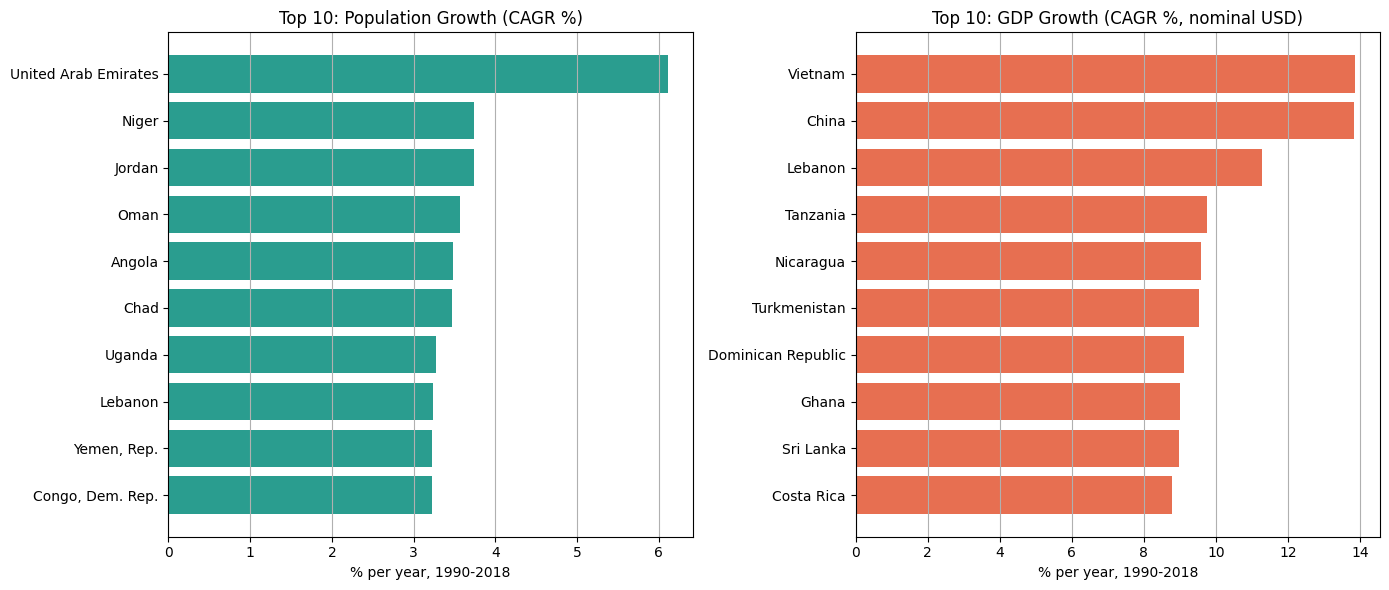

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

d1 = g.nlargest(10, 'pop_cagr').sort_values('pop_cagr')
axes[0].barh(d1['country'], d1['pop_cagr'], color='#2a9d8f')
axes[0].set_title('Top 10: Population Growth (CAGR %)')

d2 = g.nlargest(10, 'gdp_cagr').sort_values('gdp_cagr')
axes[1].barh(d2['country'], d2['gdp_cagr'], color='#e76f51')
axes[1].set_title('Top 10: GDP Growth (CAGR %, nominal USD)')

for ax in axes:
    ax.set_xlabel('% per year, 1990-2018')
    ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

**Chart 2: population vs GDP growth, the overlap chart**

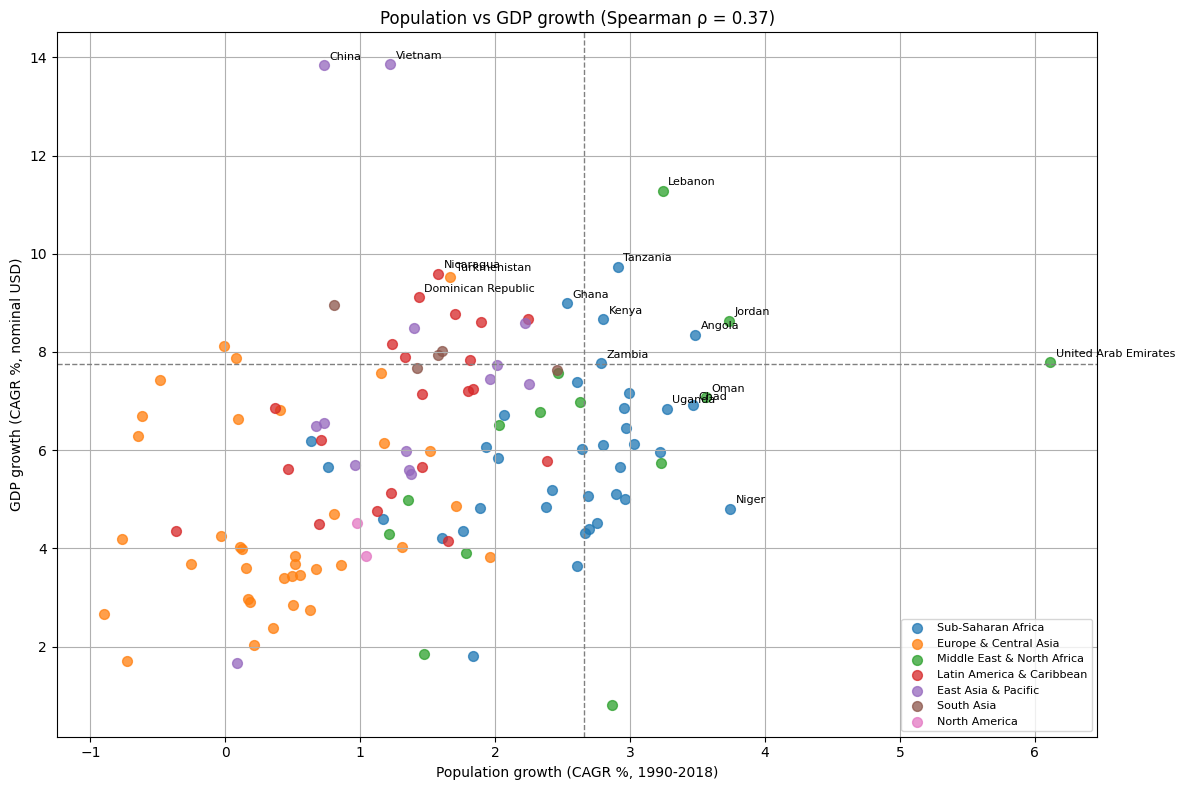

In [92]:
fig, ax = plt.subplots(figsize=(12, 8))

regions = g['region'].unique()
colors = dict(zip(regions, plt.cm.tab10.colors))
for reg in regions:
    sub = g[g['region'] == reg]
    ax.scatter(sub['pop_cagr'], sub['gdp_cagr'], s=50, alpha=0.75,
               color=colors[reg], label=reg)

# Quintile threshold lines: the top-right box is the "overlap zone"
ax.axvline(q_pop, color='grey', ls='--', lw=1)
ax.axhline(q_gdp, color='grey', ls='--', lw=1)

# Label the interesting countries
to_label = set(top_pop['country'].head(8)) | set(top_gdp['country'].head(8)) | set(both['country'])
for _, r in g[g['country'].isin(to_label)].iterrows():
    ax.annotate(r['country'], (r['pop_cagr'], r['gdp_cagr']),
                fontsize=8, xytext=(4, 4), textcoords='offset points')

ax.set_xlabel('Population growth (CAGR %, 1990-2018)')
ax.set_ylabel('GDP growth (CAGR %, nominal USD)')
ax.set_title(f'Population vs GDP growth (Spearman ρ = {rho:.2f})')
ax.legend(fontsize=8, loc='lower right')
plt.tight_layout()
import os
os.makedirs("images", exist_ok=True)
fig.savefig("images/q1_pop_vs_gdp.png", dpi=150, bbox_inches="tight")
plt.show()
#

Chart 3: Does GDP growth come from more people or from higher output per person?

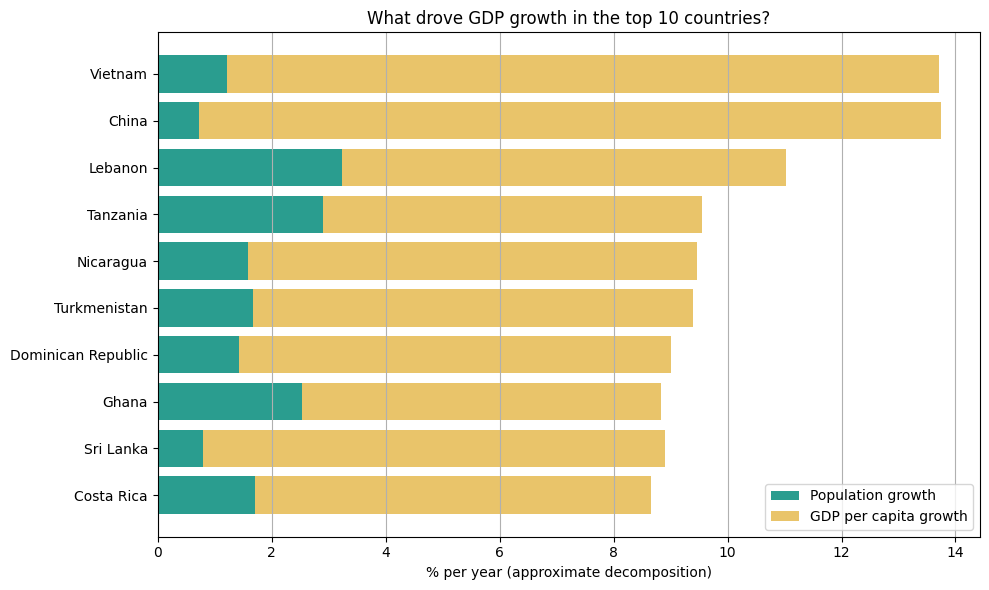

In [93]:
fig, ax = plt.subplots(figsize=(10, 6))
d = g.nlargest(10, 'gdp_cagr').sort_values('gdp_cagr')
ax.barh(d['country'], d['pop_cagr'], label='Population growth', color='#2a9d8f')
ax.barh(d['country'], d['gdppc_cagr'], left=d['pop_cagr'],
        label='GDP per capita growth', color='#e9c46a')
ax.set_xlabel('% per year (approximate decomposition)')
ax.set_title('What drove GDP growth in the top 10 countries?')
ax.legend()
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

**Step 6: Check the robustness of your result**

In [94]:
def overlap_for(start, end, min_pop=1_000_000, n=15):
    s = (wb[wb['year'].isin([start, end])]
         .pivot(index='country_code', columns='year', values=['population_est', 'gdp_usd']))
    s.columns = [f"{m}_{y}" for m, y in s.columns]
    s = s.join(meta).dropna(subset=list(s.columns))
    s = s[s[f'population_est_{start}'] >= min_pop].copy()
    yrs = end - start
    s['pop'] = cagr(s[f'population_est_{end}'], s[f'population_est_{start}'], yrs) * 100
    s['gdp'] = cagr(s[f'gdp_usd_{end}'], s[f'gdp_usd_{start}'], yrs) * 100
    ov = set(s.nlargest(n, 'pop')['country']) & set(s.nlargest(n, 'gdp')['country'])
    return len(s), sorted(ov), round(s[['pop', 'gdp']].corr(method='spearman').iloc[0, 1], 2)

for window in [(1990, 2018), (2000, 2018), (1980, 2018)]:
    print(window, overlap_for(*window))

(1990, 2018) (128, ['Jordan', 'Lebanon'], np.float64(0.37))
(2000, 2018) (142, ['Angola', 'Chad'], np.float64(0.23))
(1980, 2018) (101, ['Angola', 'Uganda'], np.float64(0.13))


**Step 7: Write up for Q1**

**Reduce base-year noise by using 3-year averages (1990-92 vs 2016-18):**

In [95]:
def growth_smoothed(start, end, k=3, min_pop=1_000_000):
    cols = ['population_est', 'gdp_usd', 'gdp_per_capita']
    first = wb[wb['year'].between(start, start + k - 1)].groupby('country_code')[cols].mean()
    last = wb[wb['year'].between(end - k + 1, end)].groupby('country_code')[cols].mean()
    s = first.join(last, lsuffix='_a', rsuffix='_b').dropna()
    s = s[s['population_est_a'] >= min_pop].join(meta)
    yrs = (end - start) - (k - 1)          # distance between the two window midpoints
    for c in ['population_est', 'gdp_usd', 'gdp_per_capita']:
        s[c + '_cagr'] = ((s[c + '_b'] / s[c + '_a']) ** (1 / yrs) - 1) * 100
    return s

s = growth_smoothed(1990, 2018)
print("Countries:", len(s))
print("Top 15 population:", s.nlargest(15, 'population_est_cagr')['country'].tolist())
print("Top 15 GDP:", s.nlargest(15, 'gdp_usd_cagr')['country'].tolist())
print("Top 15 GDP per capita:", s.nlargest(15, 'gdp_per_capita_cagr')['country'].tolist())
print("Spearman pop vs GDP:", round(s[['population_est_cagr', 'gdp_usd_cagr']].corr(method='spearman').iloc[0, 1], 2))

Countries: 131
Top 15 population: ['United Arab Emirates', 'Niger', 'Jordan', 'Oman', 'Chad', 'Angola', 'Lebanon', 'Uganda', 'Congo, Dem. Rep.', 'Yemen, Rep.', 'Benin', 'Iraq', 'Ethiopia', 'Mozambique', 'Mali']
Top 15 GDP: ['China', 'Vietnam', 'Lebanon', 'Turkmenistan', 'Tanzania', 'Angola', 'Albania', 'Sri Lanka', 'Ghana', 'Kenya', 'Nicaragua', 'Jordan', 'India', 'Panama', 'Indonesia']
Top 15 GDP per capita: ['China', 'Vietnam', 'Albania', 'Romania', 'Sri Lanka', 'Turkmenistan', 'Armenia', 'Slovak Republic', 'Poland', 'Nicaragua', 'Czech Republic', 'Indonesia', 'India', 'Dominican Republic', 'Kazakhstan']
Spearman pop vs GDP: 0.34


**Population growth vs prosperity, and a significance check on the overlap:**

In [96]:
# Does faster population growth go with faster or slower income growth per person?
rho_pc = g[['pop_cagr', 'gdppc_cagr']].corr(method='spearman').iloc[0, 1]
print("Spearman, population growth vs GDP per capita growth:", round(rho_pc, 2))

# How surprising is the quintile overlap?
from scipy.stats import hypergeom
p = hypergeom.sf(len(both) - 1, len(g), g['top_pop'].sum(), g['top_gdp'].sum())
print(f"P(overlap >= {len(both)} by chance) = {p:.2f}")

Spearman, population growth vs GDP per capita growth: -0.21
P(overlap >= 7 by chance) = 0.25


Independent check using population density. Density is reported separately (people per sq. km of land area). Land area is essentially constant, so density growth equals population growth without using the GDP series at all:

In [97]:
dens = (wb[wb['year'].isin([1990, 2018])]
        .pivot(index='country_code', columns='year', values='pop_density'))
dens.columns = ['dens_1990', 'dens_2018']
chk = g.join(dens, how='left').dropna(subset=['dens_1990', 'dens_2018'])
chk['pop_cagr_density'] = ((chk['dens_2018'] / chk['dens_1990']) ** (1 / n_years) - 1) * 100

# 1. Does density-based population growth match the derived estimate?
print("Agreement with derived population growth (Spearman):",
      round(chk[['pop_cagr', 'pop_cagr_density']].corr(method='spearman').iloc[0, 1], 3))

# 2. Independent tests, free of the GDP/GDP-per-capita identity
for target in ['gdp_cagr', 'gdppc_cagr']:
    r = chk[['pop_cagr_density', target]].corr(method='spearman').iloc[0, 1]
    print(f"Population growth (density-based) vs {target}: {r:.2f}")

Agreement with derived population growth (Spearman): 0.999
Population growth (density-based) vs gdp_cagr: 0.36
Population growth (density-based) vs gdppc_cagr: -0.21


Q1: Population and GDP growth, 1990-2018. Population grew fastest in the UAE, Niger, Jordan, Oman and Angola: Sub-Saharan Africa made up two-thirds of the top 15, and the Gulf/Levant (partly migration-driven) most of the rest. GDP (USD) grew fastest in Vietnam, China, Lebanon, Tanzania and Nicaragua, a more mixed group.

The overlap is small and unstable. Only Jordan and Lebanon are in both top-15 lists (Angola joins them using 3-year averages). Across ~130 countries the rank correlation between population and GDP growth is moderate (ρ ≈ 0.34-0.37) but weakens to 0.23 and 0.13 in other windows, and the top-quintile overlap (7 countries) is no more than chance would produce (p = 0.25).

More people did not mean more prosperity per person. Population growth was weakly negatively related to GDP per capita growth (ρ = −0.21, confirmed with density-based population growth). The fastest per-capita growers (China, Vietnam, plus post-communist economies like Poland and Romania) mostly had slow population growth.

Caveats: GDP is in [nominal/constant] USD, so inflation and exchange rates affect rankings; per-capita growth for post-communist countries benefits from a very low 1990 base; only countries with data in both years and at least 1 million people in 1990 are included (N = [exact count from Step 1]).

# Answering Q2

**Step 1: country-level change and regional summary**

In [98]:
reg = (wb.drop_duplicates('country_code')
         .set_index('country_code')[['country', 'region', 'income_simple']])

h = (hdi_panel[hdi_panel['year'].isin([2000, 2019, 2021])]
     .pivot(index='iso3', columns='year', values='hdi'))
h.columns = [f'hdi_{y}' for y in h.columns]
h = h.join(reg, how='inner')          # drops FSM, LAO, NRU (no World Bank region)

print("Countries matched:", len(h))
print("Missing HDI:\n", h[['hdi_2000', 'hdi_2019', 'hdi_2021']].isna().sum())

h = h.dropna(subset=['hdi_2000', 'hdi_2021']).copy()
h['change_abs'] = h['hdi_2021'] - h['hdi_2000']
h['change_pct'] = (h['hdi_2021'] / h['hdi_2000'] - 1) * 100
h['change_abs_2019'] = h['hdi_2019'] - h['hdi_2000']

summary = (h.groupby('region')
             .agg(n=('country', 'count'),
                  hdi_2000=('hdi_2000', 'mean'),
                  hdi_2021=('hdi_2021', 'mean'),
                  abs_change=('change_abs', 'mean'),
                  median_change=('change_abs', 'median'),
                  pct_change=('change_pct', 'mean'),
                  abs_change_to_2019=('change_abs_2019', 'mean'))
             .sort_values('abs_change', ascending=False))
display(summary.round(3))

print("\nTop 10 countries by absolute HDI gain:")
display(h.nlargest(10, 'change_abs')[['country', 'region', 'hdi_2000', 'hdi_2021', 'change_abs']].round(3))
print("Bottom 5 (smallest gain or decline):")
display(h.nsmallest(5, 'change_abs')[['country', 'region', 'hdi_2000', 'hdi_2021', 'change_abs']].round(3))

Countries matched: 192
Missing HDI:
 hdi_2000    20
hdi_2019     3
hdi_2021     3
dtype: int64


,n,hdi_2000,hdi_2021,abs_change,median_change,pct_change,abs_change_to_2019
region,,,,,,,
South Asia,7,0.51,0.64,0.13,0.14,27.54,0.13
Sub-Saharan Africa,43,0.44,0.55,0.11,0.11,28.67,0.12
East Asia & Pacific,24,0.67,0.76,0.09,0.08,15.07,0.09
Europe & Central Asia,48,0.77,0.86,0.09,0.08,11.57,0.09
Middle East & North Africa,19,0.67,0.75,0.08,0.09,13.00,0.09
Latin America & Caribbean,29,0.67,0.74,0.07,0.07,10.15,0.08
North America,2,0.89,0.93,0.04,0.04,4.27,0.04



Top 10 countries by absolute HDI gain:


,country,region,hdi_2000,hdi_2021,change_abs
ETH,Ethiopia,Sub-Saharan Africa,0.29,0.50,0.21
AGO,Angola,Sub-Saharan Africa,0.38,0.59,0.21
RWA,Rwanda,Sub-Saharan Africa,0.34,0.53,0.19
CHN,China,East Asia & Pacific,0.58,0.77,0.18
BGD,Bangladesh,South Asia,0.48,0.66,0.18
MMR,Myanmar,East Asia & Pacific,0.41,0.58,0.17
KHM,Cambodia,East Asia & Pacific,0.42,0.59,0.17
TUR,Turkey,Europe & Central Asia,0.67,0.84,0.17
MAR,Morocco,Middle East & North Africa,0.52,0.68,0.16
SLE,Sierra Leone,Sub-Saharan Africa,0.32,0.48,0.16


Bottom 5 (smallest gain or decline):


,country,region,hdi_2000,hdi_2021,change_abs
SYR,Syrian Arab Republic,Middle East & North Africa,0.59,0.58,-0.01
YEM,"Yemen, Rep.",Middle East & North Africa,0.45,0.46,0.01
LBY,Libya,Middle East & North Africa,0.71,0.72,0.01
VEN,"Venezuela, RB",Latin America & Caribbean,0.68,0.69,0.01
BHS,"Bahamas, The",Latin America & Caribbean,0.80,0.81,0.01


The n column matters: North America has only 2 or 3 countries (Bermuda has no HDI), so any claim about it is weak. South Asia has 8, which is also small. Show n in your chart labels.

**Step 2: charts**

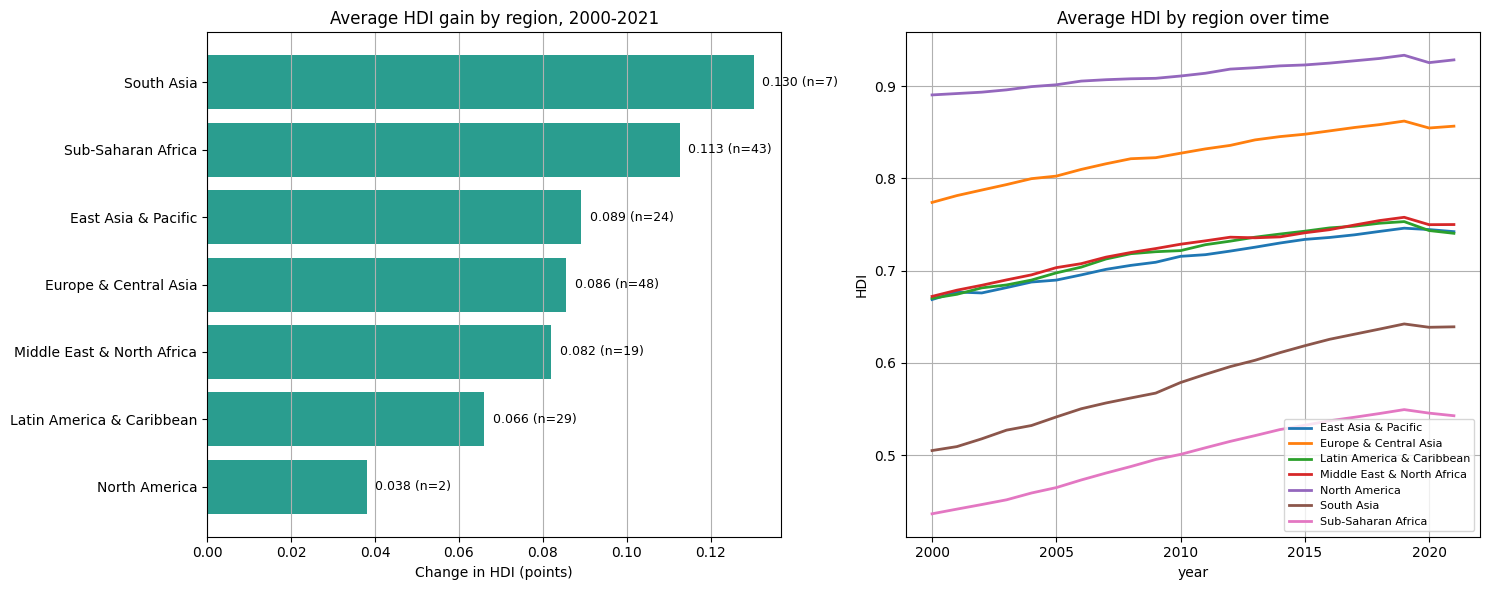

In [121]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# (a) Gain by region
s = summary.sort_values('abs_change')
axes[0].barh(s.index, s['abs_change'], color='#2a9d8f')
for i, (v, n) in enumerate(zip(s['abs_change'], s['n'])):
    axes[0].text(v + 0.002, i, f"{v:.3f} (n={n})", va='center', fontsize=9)
axes[0].set_title('Average HDI gain by region, 2000-2021')
axes[0].set_xlabel('Change in HDI (points)')
axes[0].grid(axis='y', visible=False)

# (b) Trend over time
panel = (hdi_panel[hdi_panel['year'] >= 2000]
         .merge(reg[['region']], left_on='iso3', right_index=True))
trend = panel.groupby(['year', 'region'])['hdi'].mean().unstack()
trend.plot(ax=axes[1], lw=2)
axes[1].set_title('Average HDI by region over time')
axes[1].set_ylabel('HDI')
axes[1].legend(fontsize=8)

plt.tight_layout()
import os
os.makedirs("images", exist_ok=True)
fig.savefig("images/q1_pop_vs_gdp.png", dpi=150, bbox_inches="tight")
plt.show()

**Step 3: is it simply catch-up? (starting level vs gain)**

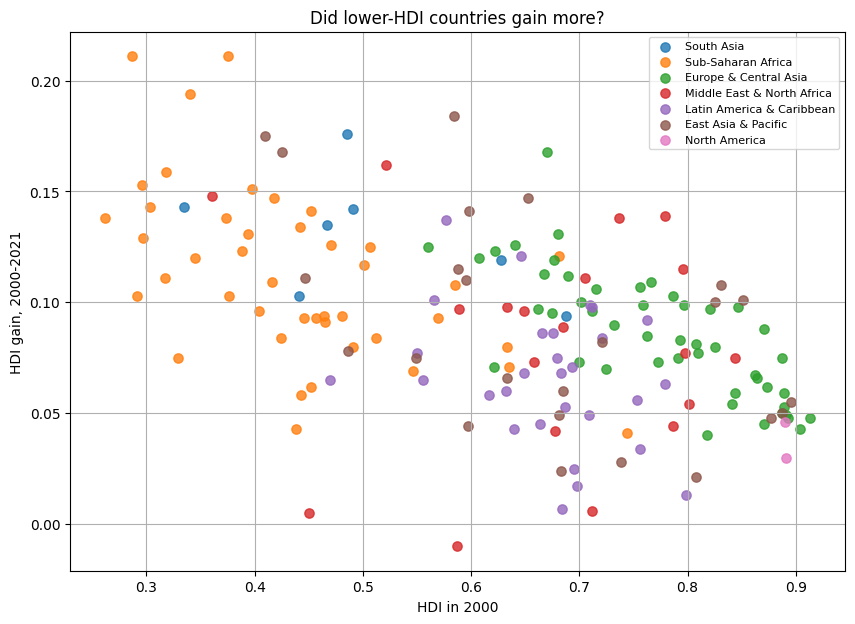

Spearman, starting HDI vs gain: -0.53


In [100]:
fig, ax = plt.subplots(figsize=(10, 7))
for r, c in zip(h['region'].unique(), plt.cm.tab10.colors):
    d = h[h['region'] == r]
    ax.scatter(d['hdi_2000'], d['change_abs'], label=r, color=c, alpha=0.8, s=45)
ax.set_xlabel('HDI in 2000')
ax.set_ylabel('HDI gain, 2000-2021')
ax.set_title('Did lower-HDI countries gain more?')
ax.legend(fontsize=8)
plt.show()

print("Spearman, starting HDI vs gain:",
      round(h[['hdi_2000', 'change_abs']].corr(method='spearman').iloc[0, 1], 2))

If starting HDI is negatively correlated with the gain, regions that began low (Sub-Saharan Africa, South Asia) will tend to top the ranking simply because HDI has a ceiling of 1. The change_pct column gives a view that favours low starting points even more, so report both absolute and percentage gain and say which you’re using as the headline.

**Step 4: robustness**

In [101]:
# Region ranking by each version of the metric
ranks = summary[['abs_change', 'median_change', 'pct_change', 'abs_change_to_2019']].rank(ascending=False)
display(ranks)

,abs_change,median_change,pct_change,abs_change_to_2019
region,,,,
South Asia,1.00,1.00,2.00,1.00
Sub-Saharan Africa,2.00,2.00,1.00,2.00
East Asia & Pacific,3.00,5.00,3.00,3.00
Europe & Central Asia,4.00,4.00,5.00,4.00
Middle East & North Africa,5.00,3.00,4.00,5.00
Latin America & Caribbean,6.00,6.00,6.00,6.00
North America,7.00,7.00,7.00,7.00


If the top region is the same under all four, it’s a robust conclusion. If the ranking changes, report which choice drives it.

**Who’s missing, and the catch-up-adjusted ranking:**

In [102]:
# Countries dropped because they have no HDI in 2000
h2000 = hdi_panel[hdi_panel['year'] == 2000].set_index('iso3')['hdi']
missing_2000 = reg[reg.index.isin(hdi_codes)].join(h2000.rename('hdi_2000'))
missing_2000 = missing_2000[missing_2000['hdi_2000'].isna()]
print(len(missing_2000), "countries missing HDI in 2000:")
print(missing_2000[['country', 'region']].sort_values('region').to_string())

# Catch-up: Spearman, then the gain each country achieved beyond what its starting HDI predicts
rho = h[['hdi_2000', 'change_abs']].corr(method='spearman').iloc[0, 1]
print("\nSpearman, starting HDI vs gain:", round(rho, 2))

slope, intercept = np.polyfit(h['hdi_2000'], h['change_abs'], 1)
h['gain_vs_expected'] = h['change_abs'] - (intercept + slope * h['hdi_2000'])

adj = (h.groupby('region')['gain_vs_expected']
         .agg(mean='mean', median='median', n='count')
         .sort_values('mean', ascending=False))
display(adj.round(3))

20 countries missing HDI in 2000:
                          country                      region
country_code                                                 
TLS                   Timor-Leste         East Asia & Pacific
MHL              Marshall Islands         East Asia & Pacific
VUT                       Vanuatu         East Asia & Pacific
PRK                   North Korea         East Asia & Pacific
TKM                  Turkmenistan       Europe & Central Asia
MCO                        Monaco       Europe & Central Asia
MNE                    Montenegro       Europe & Central Asia
SMR                    San Marino       Europe & Central Asia
ATG           Antigua and Barbuda   Latin America & Caribbean
GRD                       Grenada   Latin America & Caribbean
SUR                      Suriname   Latin America & Caribbean
KNA           St. Kitts and Nevis   Latin America & Caribbean
PSE            West Bank and Gaza  Middle East & North Africa
LBN                       Lebanon  M

,mean,median,n
region,,,
South Asia,0.02,0.02,7
Europe & Central Asia,0.01,0.01,48
East Asia & Pacific,0.00,-0.00,24
Sub-Saharan Africa,-0.00,-0.01,43
Middle East & North Africa,-0.00,0.01,19
North America,-0.02,-0.02,2
Latin America & Caribbean,-0.02,-0.02,29


A positive value means a region gained more than countries with the same starting HDI typically did, and a negative value means less. If South Asia is still near the top, it outperformed on more than catch-up. If everything moves close to zero, most of the ranking was catch-up. The linear fit is a simple approximation, so treat the output as indicative only.

**Fixed trend chart with a constant set of countries:**

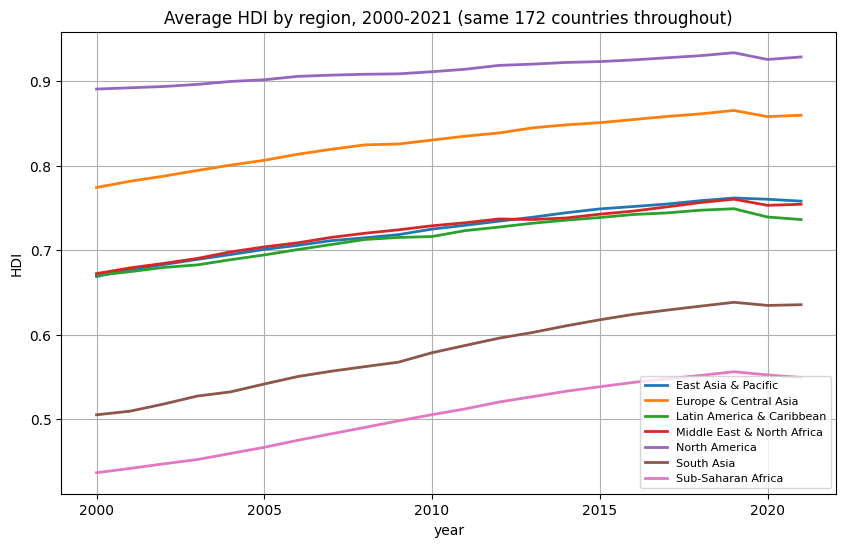

In [103]:
balanced = h.index   # countries with HDI in both 2000 and 2021
panel = (hdi_panel[(hdi_panel['year'] >= 2000) & hdi_panel['iso3'].isin(balanced)]
         .merge(reg[['region']], left_on='iso3', right_index=True))
trend = panel.groupby(['year', 'region'])['hdi'].mean().unstack()

fig, ax = plt.subplots(figsize=(10, 6))
trend.plot(ax=ax, lw=2)
ax.set_title('Average HDI by region, 2000-2021 (same 172 countries throughout)')
ax.set_ylabel('HDI')
ax.legend(fontsize=8)
plt.show()

**Robustness check: include the missing countries**

This uses each country’s first available HDI year from 2000 onwards, and reports the gain per year so countries with different start years are comparable:

In [104]:
p = hdi_panel[(hdi_panel['year'] >= 2000) & hdi_panel['hdi'].notna()].sort_values('year')
first = p.groupby('iso3').first()[['year', 'hdi']]
last = p.groupby('iso3').last()[['year', 'hdi']]
a = first.join(last, lsuffix='_a', rsuffix='_b').join(reg, how='inner')
a = a[(a['year_b'] == 2021) & (a['year_b'] - a['year_a'] >= 10)].copy()
a['pts_per_year'] = (a['hdi_b'] - a['hdi_a']) / (a['year_b'] - a['year_a'])

print("Countries:", len(a))
print("Start years:\n", a['year_a'].value_counts().sort_index())

robust = (a.groupby('region')['pts_per_year']
            .agg(mean='mean', median='median', n='count')
            .sort_values('mean', ascending=False))
display((robust * [1000, 1000, 1]).round(2))   # HDI points per 1,000 per year

Countries: 188
Start years:
 year_a
2000    172
2002      3
2003      2
2004      2
2005      5
2007      1
2010      2
2011      1
Name: count, dtype: int64


,mean,median,n
region,,,
South Asia,6.39,6.60,8
Sub-Saharan Africa,5.10,4.94,47
Europe & Central Asia,4.10,4.12,50
East Asia & Pacific,4.06,3.71,27
Middle East & North Africa,3.62,3.76,21
Latin America & Caribbean,2.98,3.10,33
North America,1.81,1.81,2


Q2: Which regions gained the most HDI in the 21st century? Between 2000 and 2021, South Asia (+0.130, n=7) and Sub-Saharan Africa (+0.113, n=43) gained the most, ranking first and second under every measure tested (mean, median, percentage, and a 2019 end-point that excludes the COVID dip). Latin America & Caribbean (+0.066) and North America (+0.038, n=2) gained the least; East Asia & Pacific, Europe & Central Asia and MENA were closely bunched (+0.082 to +0.089).

Most of this is catch-up. Starting HDI and gain are strongly negatively correlated (ρ = -0.53), since HDI is capped at 1. After adjusting for starting level, regional differences shrink to about ±0.02 points: Sub-Saharan Africa’s advantage disappears, South Asia keeps a small edge (+0.02, though only 7 countries), and Latin America & Caribbean falls slightly short (-0.02). The fastest-improving individual countries were Ethiopia, Angola, Rwanda, China and Bangladesh.

Caveats: 172 of 192 matched countries have HDI in both 2000 and 2021; the 20 missing include Nigeria and several conflict-affected states, which could bias some regional averages upward [update after the robustness check]. Regional averages are unweighted by population. HDI dipped in most regions in 2020-2021. The catch-up adjustment is a simple linear fit.

# Answering Q3

##Q3: Which factors are highly correlated with life expectancy?

**Step 1: choose the year by checking pairwise coverage**

In [105]:
factors = ['gdp_per_capita', 'electricity_kwh_pc', 'internet_pct', 'infant_mortality',
           'birth_rate', 'death_rate', 'pop_density', 'unemployment_pct']

for y in range(2010, 2019):
    d = wb[wb['year'] == y]
    n_all = d[['life_expectancy'] + factors].dropna().shape[0]
    n_le = d['life_expectancy'].notna().sum()
    print(y, "| life exp:", n_le, "| all factors complete:", n_all)

2010 | life exp: 197 | all factors complete: 134
2011 | life exp: 197 | all factors complete: 134
2012 | life exp: 199 | all factors complete: 132
2013 | life exp: 197 | all factors complete: 133
2014 | life exp: 197 | all factors complete: 133
2015 | life exp: 197 | all factors complete: 0
2016 | life exp: 196 | all factors complete: 0
2017 | life exp: 196 | all factors complete: 0
2018 | life exp: 0 | all factors complete: 0


Pick the latest year where the number of countries is still reasonably high (the 2014-2016 range is my guess, so check). Complete rows may be much fewer than the life expectancy count, so the next step uses pairwise correlations instead.

**Step 2: correlations with counts**

In [106]:
YEAR = 2015     # change after checking Step 1
d = wb[wb['year'] == YEAR].copy()

rows = []
for f in factors:
    pair = d[['life_expectancy', f]].dropna()
    rows.append({'factor': f,
                 'spearman': pair.corr(method='spearman').iloc[0, 1],
                 'pearson': pair.corr(method='pearson').iloc[0, 1],
                 'n': len(pair)})
corr = (pd.DataFrame(rows)
          .assign(abs_sp=lambda x: x['spearman'].abs())
          .sort_values('abs_sp', ascending=False)
          .drop(columns='abs_sp')
          .set_index('factor'))
display(corr.round(2))

,spearman,pearson,n
factor,,,
infant_mortality,-0.93,-0.94,182
birth_rate,-0.86,-0.88,197
gdp_per_capita,0.86,0.60,188
internet_pct,0.86,0.83,193
pop_density,0.30,0.20,194
death_rate,-0.18,-0.28,197
unemployment_pct,0.11,0.03,186
electricity_kwh_pc,NaN,NaN,1


**Step 3: charts**

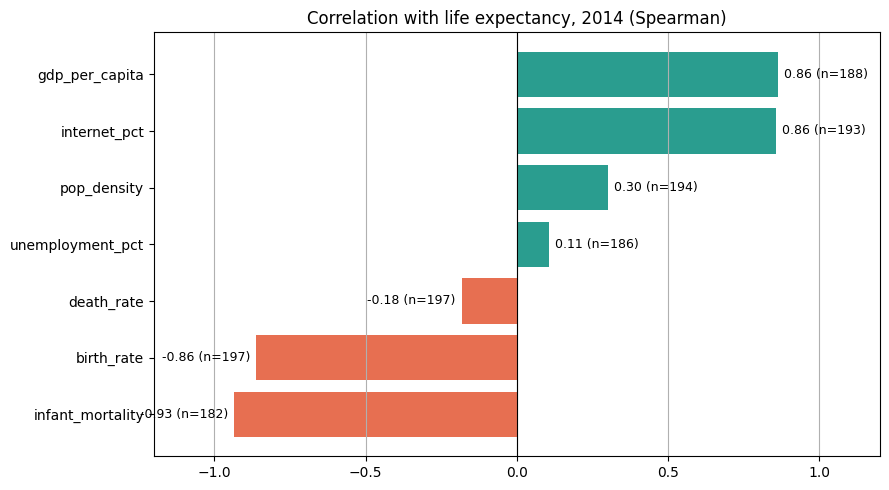

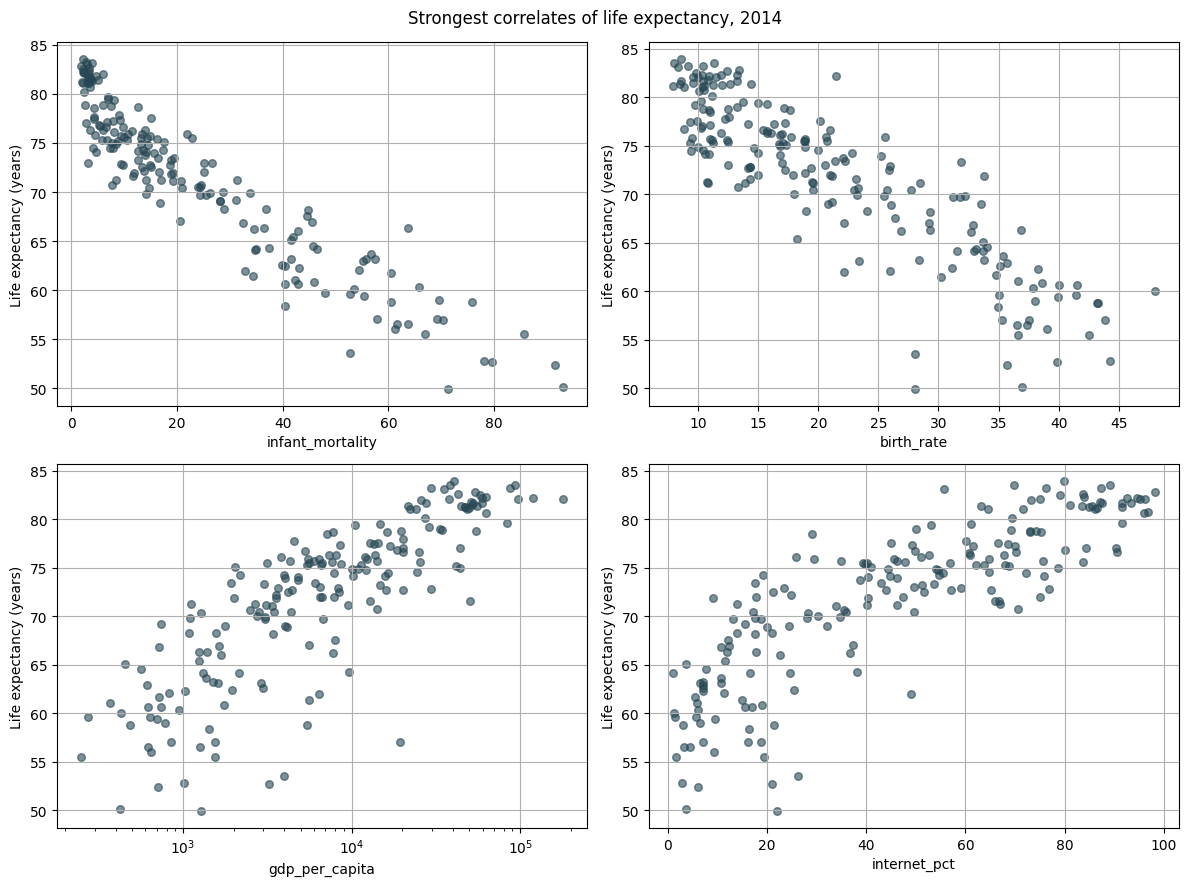

In [122]:
# Bar chart of correlations
fig, ax = plt.subplots(figsize=(9, 5))
c = corr['spearman'].sort_values()
ax.barh(c.index, c.values, color=['#e76f51' if v < 0 else '#2a9d8f' for v in c.values])
for i, (v, f) in enumerate(zip(c.values, c.index)):
    ax.text(v + (0.02 if v >= 0 else -0.02), i, f"{v:.2f} (n={corr.loc[f, 'n']})",
            va='center', ha='left' if v >= 0 else 'right', fontsize=9)
ax.set_xlim(-1.2, 1.2)
ax.axvline(0, color='black', lw=0.8)
ax.set_title(f'Correlation with life expectancy, {YEAR} (Spearman)')
ax.grid(axis='y', visible=False)
plt.tight_layout()
import os
os.makedirs("images", exist_ok=True)
fig.savefig("images/q1_pop_vs_gdp.png", dpi=150, bbox_inches="tight")
plt.show()

# Scatter plots for the strongest factors (log scale for skewed variables)
top4 = corr.index[:4]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, f in zip(axes.ravel(), top4):
    ax.scatter(d[f], d['life_expectancy'], alpha=0.6, s=30, color='#264653')
    if f in ('gdp_per_capita', 'electricity_kwh_pc', 'pop_density'):
        ax.set_xscale('log')
    ax.set_xlabel(f)
    ax.set_ylabel('Life expectancy (years)')
plt.suptitle(f'Strongest correlates of life expectancy, {YEAR}')
plt.tight_layout()
plt.show()

**Step 4: does the relationship survive within income groups?**

A factor can look strongly related overall just because rich and poor countries differ on everything. Compare within each group:

In [108]:
within = (d.groupby('income_simple', observed=True)
            .apply(lambda x: x[['life_expectancy'] + factors].corr(method='spearman')['life_expectancy'])
            .drop(columns='life_expectancy'))
display(within.round(2))

/tmp/ipykernel_2190/2304807785.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x[['life_expectancy'] + factors].corr(method='spearman')['life_expectancy'])


life_expectancy,gdp_per_capita,electricity_kwh_pc,internet_pct,infant_mortality,birth_rate,death_rate,pop_density,unemployment_pct
income_simple,,,,,,,,
Low income,0.28,NaN,0.35,-0.82,-0.67,-0.89,0.59,-0.49
Lower middle income,0.49,NaN,0.40,-0.88,-0.63,-0.55,0.35,-0.10
Upper middle income,0.25,NaN,0.36,-0.68,-0.63,-0.28,0.44,-0.10
High income,0.66,NaN,0.55,-0.75,-0.54,-0.06,0.28,-0.15


Correlations that stay strong inside each income group are more convincing than ones that vanish.

In [109]:
YEAR = 2014
d = wb[wb['year'] == YEAR].copy()
print(d['electricity_kwh_pc'].notna().sum(), "countries with electricity data in", YEAR)

139 countries with electricity data in 2014


Group sizes and correlations together (use after switching to 2014):

In [110]:
rows = {}
for grp, x in d.groupby('income_simple', observed=True):
    r = {f: x[['life_expectancy', f]].dropna().corr(method='spearman').iloc[0, 1] for f in factors}
    r['n_countries'] = x['life_expectancy'].notna().sum()
    rows[grp] = r
display(pd.DataFrame(rows).T.round(2))

,gdp_per_capita,electricity_kwh_pc,internet_pct,infant_mortality,birth_rate,death_rate,pop_density,unemployment_pct,n_countries
Low income,0.13,0.04,0.35,-0.81,-0.67,-0.92,0.61,-0.48,31.00
Lower middle income,0.43,0.60,0.50,-0.89,-0.63,-0.57,0.35,-0.07,48.00
Upper middle income,0.12,0.08,0.41,-0.68,-0.64,-0.29,0.44,-0.10,48.00
High income,0.64,0.29,0.49,-0.74,-0.49,-0.06,0.28,-0.15,70.00


Pearson on log income (checks the curved relationship):

In [111]:
pair = d[['life_expectancy', 'gdp_per_capita']].dropna()
print("Pearson, life expectancy vs log10(GDP per capita):",
      round(np.corrcoef(pair['life_expectancy'], np.log10(pair['gdp_per_capita']))[0, 1], 2))

Pearson, life expectancy vs log10(GDP per capita): 0.82


Factors vs each other (shows which factors are overlapping measures of the same thing):

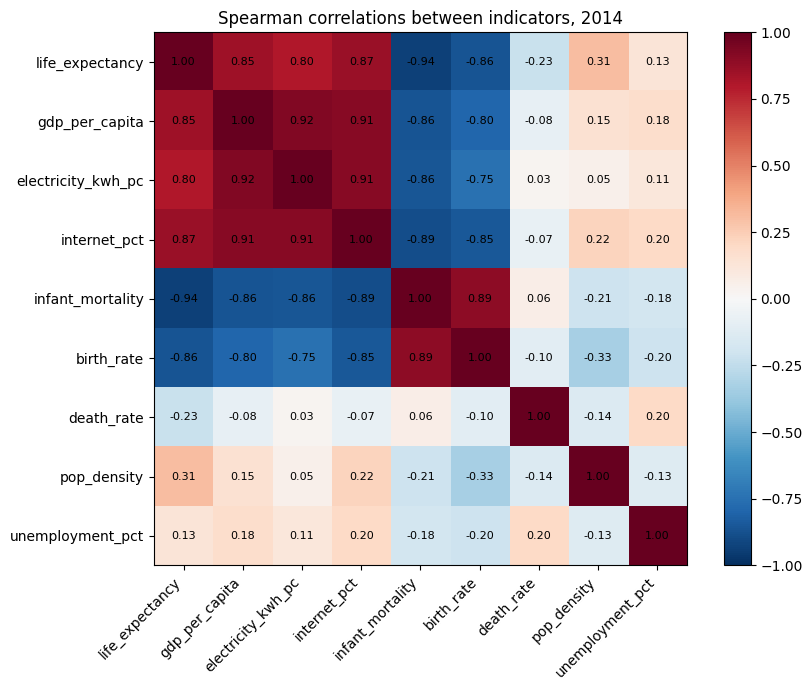

In [112]:
cm = d[['life_expectancy'] + factors].corr(method='spearman')
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cm, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(cm))); ax.set_xticklabels(cm.columns, rotation=45, ha='right')
ax.set_yticks(range(len(cm))); ax.set_yticklabels(cm.index)
for i in range(len(cm)):
    for j in range(len(cm)):
        ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha='center', va='center', fontsize=8)
ax.grid(False)
plt.colorbar(im)
ax.set_title(f'Spearman correlations between indicators, {YEAR}')
plt.tight_layout()
plt.show()

Stability across years:

In [113]:
stab = pd.DataFrame({
    y: wb[wb['year'] == y][['life_expectancy'] + factors]
         .corr(method='spearman')['life_expectancy'].drop('life_expectancy')
    for y in [1995, 2000, 2005, 2010, 2014]})
display(stab.round(2))

,1995,2000,2005,2010,2014
gdp_per_capita,0.87,0.86,0.83,0.84,0.85
electricity_kwh_pc,0.78,0.80,0.78,0.79,0.80
internet_pct,0.75,0.84,0.86,0.88,0.87
infant_mortality,-0.94,-0.94,-0.93,-0.93,-0.94
birth_rate,-0.82,-0.80,-0.81,-0.83,-0.86
death_rate,-0.60,-0.57,-0.52,-0.40,-0.23
pop_density,0.34,0.34,0.34,0.33,0.31
unemployment_pct,0.15,0.05,0.04,0.11,0.13


Q3: Which factors are highly correlated with life expectancy? In 2014 ([N] countries), life expectancy was most strongly related to infant mortality (ρ = -0.94), internet use (+0.87), birth rate (-0.86), GDP per capita (+0.85) and electricity use (+0.80, n=[x]). Population density (+0.31), unemployment (+0.13) and the crude death rate (-0.23) showed weak or no relationship. The strong correlations were stable from 1995 to 2014, apart from internet use (which rose as adoption spread) and the death rate (which weakened from -0.60).

Interpretation. The strong factors largely measure the same thing: overall development. Internet use and GDP per capita correlate 0.91 with each other, and infant mortality and birth rate 0.90. Infant mortality is also partly built into life expectancy at birth. Within income groups, GDP and internet use correlate only about 0.25-0.66 with life expectancy, while infant mortality (-0.68 to -0.88) and birth rate (-0.54 to -0.67) stay consistently strong. These are correlations, not causes: internet access doesn’t extend life, it travels with wealth, health care and education.

Caveats: one cross-section year (2014, chosen as the latest with electricity data); income groups are fixed labels; correlations are rank-based (Spearman); within-group results rest on 31-70 countries each.

# Answering Q4

## Q4: What differentiates High income from Low income countries?

**Step 1: medians and the gradient across all four groups**

In [114]:
YEAR = 2014
d = wb[wb['year'] == YEAR].copy()

cols = ['life_expectancy', 'infant_mortality', 'birth_rate', 'death_rate',
        'internet_pct', 'electricity_kwh_pc', 'pop_density', 'unemployment_pct']

med = d.groupby('income_simple', observed=True)[cols].median().T
med['high_vs_low_ratio'] = med['High income'] / med['Low income']
display(med.round(2))

print("Non-missing counts (Low | High):")
cnt = d[d['income_simple'].isin(['Low income', 'High income'])] \
        .groupby('income_simple', observed=True)[cols].count().T
display(cnt)

income_simple,Low income,Lower middle income,Upper middle income,High income,high_vs_low_ratio
life_expectancy,60.34,69.85,74.61,79.58,1.32
infant_mortality,54.50,28.10,14.20,3.90,0.07
birth_rate,36.63,26.85,17.62,11.26,0.31
death_rate,9.02,6.38,7.11,7.90,0.88
internet_pct,6.23,22.28,45.59,76.01,12.20
electricity_kwh_pc,108.52,696.35,"2,182.51","6,720.38",61.93
pop_density,64.28,78.15,71.21,129.74,2.02
unemployment_pct,3.58,6.48,7.47,6.95,1.94


Non-missing counts (Low | High):


income_simple,Low income,High income
life_expectancy,31,70
infant_mortality,31,59
birth_rate,31,74
death_rate,31,74
internet_pct,30,70
electricity_kwh_pc,13,52
pop_density,29,79
unemployment_pct,31,61


**Step 2: separation scores**

In [115]:
sub = d[d['income_simple'].isin(['Low income', 'High income'])]

def auc_high_vs_low(col):
    s = sub[[col, 'income_simple']].dropna()
    ranks = s[col].rank()                      # ties get average ranks
    is_high = (s['income_simple'] == 'High income')
    n1, n0 = is_high.sum(), (~is_high).sum()
    u = ranks[is_high].sum() - n1 * (n1 + 1) / 2
    return u / (n1 * n0), n1, n0

rows = []
for c in cols:
    a, n1, n0 = auc_high_vs_low(c)
    rows.append({'indicator': c, 'auc': a, 'separation': max(a, 1 - a),
                 'direction': 'higher in High income' if a > 0.5 else 'lower in High income',
                 'n_high': n1, 'n_low': n0})
sep = pd.DataFrame(rows).sort_values('separation', ascending=False).set_index('indicator')
display(sep.round(2))

,auc,separation,direction,n_high,n_low
indicator,,,,,
electricity_kwh_pc,1.00,1.00,higher in High income,52,13
internet_pct,1.00,1.00,higher in High income,70,30
life_expectancy,0.99,0.99,higher in High income,70,31
birth_rate,0.01,0.99,lower in High income,74,31
infant_mortality,0.01,0.99,lower in High income,59,31
unemployment_pct,0.75,0.75,higher in High income,61,31
death_rate,0.34,0.66,lower in High income,74,31
pop_density,0.61,0.61,higher in High income,79,29


**Step 3: charts**

/tmp/ipykernel_2190/3953876749.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(data, labels=labels)


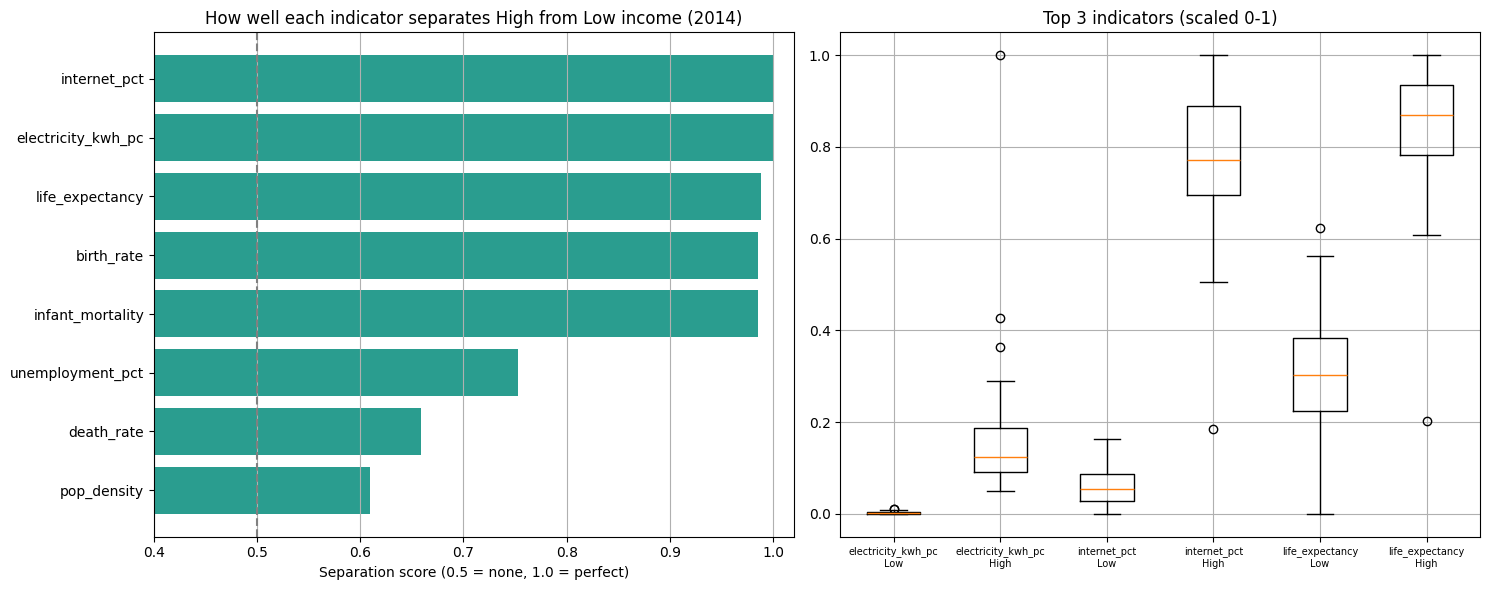

In [116]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

s = sep['separation'].sort_values()
axes[0].barh(s.index, s.values, color='#2a9d8f')
axes[0].axvline(0.5, color='grey', ls='--')
axes[0].set_xlim(0.4, 1.02)
axes[0].set_title('How well each indicator separates High from Low income (2014)')
axes[0].set_xlabel('Separation score (0.5 = none, 1.0 = perfect)')
axes[0].grid(axis='y', visible=False)

# Box plots for the top 3 on the same axis, with each indicator scaled 0-1 for comparability
top3 = sep.index[:3]
scaled = sub[top3].apply(lambda x: (x - x.min()) / (x.max() - x.min()))
data, labels = [], []
for c in top3:
    for g_name in ['Low income', 'High income']:
        data.append(scaled.loc[sub['income_simple'] == g_name, c].dropna())
        labels.append(f"{c}\n{g_name.split()[0]}")
axes[1].boxplot(data, labels=labels)
axes[1].tick_params(axis='x', labelsize=7)
axes[1].set_title('Top 3 indicators (scaled 0-1)')

plt.tight_layout()
plt.show()

**Step 4: check that it holds up**

In [117]:
# (a) Same ranking in other years?
for y in [2000, 2010, 2014]:
    sub_y = wb[(wb['year'] == y) & wb['income_simple'].isin(['Low income', 'High income'])]
    out = {}
    for c in cols:
        s_ = sub_y[[c, 'income_simple']].dropna()
        if s_['income_simple'].nunique() < 2:
            continue
        r = s_[c].rank(); h_ = s_['income_simple'] == 'High income'
        a = (r[h_].sum() - h_.sum() * (h_.sum() + 1) / 2) / (h_.sum() * (~h_).sum())
        out[c] = round(max(a, 1 - a), 2)
    print(y, out)

# (b) For reference only: income itself (circular, not a finding)
a, _, _ = auc_high_vs_low('gdp_per_capita')
print("GDP per capita separation (circular, shown for reference):", round(max(a, 1 - a), 2))

2000 {'life_expectancy': np.float64(0.99), 'infant_mortality': np.float64(0.99), 'birth_rate': np.float64(0.99), 'death_rate': np.float64(0.93), 'internet_pct': np.float64(0.99), 'electricity_kwh_pc': np.float64(1.0), 'pop_density': np.float64(0.64), 'unemployment_pct': np.float64(0.73)}
2010 {'life_expectancy': np.float64(0.99), 'infant_mortality': np.float64(0.99), 'birth_rate': np.float64(0.98), 'death_rate': np.float64(0.79), 'internet_pct': np.float64(1.0), 'electricity_kwh_pc': np.float64(1.0), 'pop_density': np.float64(0.62), 'unemployment_pct': np.float64(0.77)}
2014 {'life_expectancy': np.float64(0.99), 'infant_mortality': np.float64(0.99), 'birth_rate': np.float64(0.99), 'death_rate': np.float64(0.66), 'internet_pct': np.float64(1.0), 'electricity_kwh_pc': np.float64(1.0), 'pop_density': np.float64(0.61), 'unemployment_pct': np.float64(0.75)}
GDP per capita separation (circular, shown for reference): 1.0


Spread within groups, not just medians:

In [118]:
def fmt(x):
    return f"{x.median():,.1f} ({x.quantile(.25):,.1f}-{x.quantile(.75):,.1f})"

tbl = pd.DataFrame({grp: {c: fmt(sub.loc[sub['income_simple'] == grp, c].dropna()) for c in cols}
                    for grp in ['Low income', 'High income']})
display(tbl)   # median (25th-75th percentile)

,Low income,High income
life_expectancy,60.3 (57.7-63.1),79.6 (76.6-81.8)
infant_mortality,54.5 (42.0-64.7),3.9 (3.0-7.0)
birth_rate,36.6 (33.9-40.0),11.3 (10.2-14.3)
death_rate,9.0 (7.7-10.5),7.9 (6.2-9.2)
internet_pct,6.2 (3.6-9.4),76.0 (68.6-87.3)
electricity_kwh_pc,108.5 (69.2-271.4),"6,720.4 (4,982.9-10,126.4)"
pop_density,64.3 (35.1-184.1),129.7 (35.9-328.7)
unemployment_pct,3.6 (1.8-6.1),7.0 (5.2-10.3)


Who’s missing from electricity, and who are the exceptions:

In [119]:
print("Electricity data available, by income group:")
print(d.groupby('income_simple', observed=True)['electricity_kwh_pc']
        .apply(lambda x: f"{x.notna().sum()}/{len(x)}"))

show_cols = ['country', 'life_expectancy', 'infant_mortality', 'internet_pct']
print("\nHigh income countries with the lowest life expectancy:")
display(sub[sub['income_simple'] == 'High income'].nsmallest(5, 'life_expectancy')[show_cols])
print("Low income countries with the highest life expectancy:")
display(sub[sub['income_simple'] == 'Low income'].nlargest(5, 'life_expectancy')[show_cols])

Electricity data available, by income group:
income_simple
Low income             13/31
Lower middle income    33/48
Upper middle income    41/53
High income            52/79
Name: electricity_kwh_pc, dtype: object

High income countries with the lowest life expectancy:


,country,life_expectancy,infant_mortality,internet_pct
3485,Equatorial Guinea,57.00,70.40,18.86
9149,Russian Federation,70.74,7.70,70.52
4429,Greenland,71.54,NaN,66.70
12040,"Venezuela, RB",72.76,14.90,57.00
11214,Trinidad and Tobago,72.77,18.60,65.10


Low income countries with the highest life expectancy:


,country,life_expectancy,infant_mortality,internet_pct
8146,North Korea,71.20,17.00,NaN
7733,Nepal,69.17,31.10,15.44
1892,Cambodia,68.27,28.90,14.00
9208,Rwanda,66.88,32.50,10.60
6671,Madagascar,65.13,41.60,3.70


Better chart: all four groups in natural units:

/tmp/ipykernel_2190/602507508.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=['Low', 'Lower-mid', 'Upper-mid', 'High'])
/tmp/ipykernel_2190/602507508.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=['Low', 'Lower-mid', 'Upper-mid', 'High'])
/tmp/ipykernel_2190/602507508.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=['Low', 'Lower-mid', 'Upper-mid', 'High'])
/tmp/ipykernel_2190/602507508.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old nam

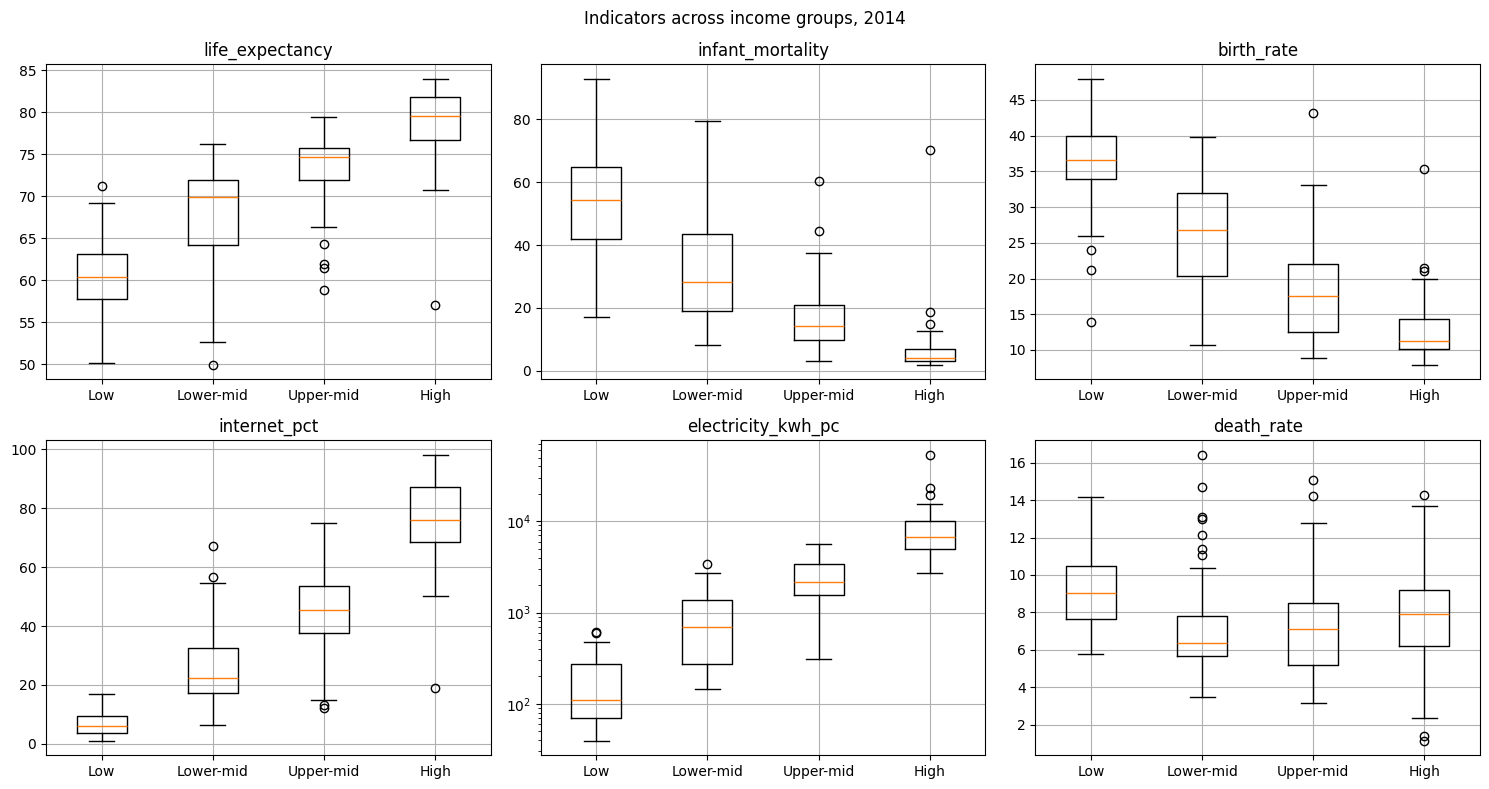

In [120]:
order = ['Low income', 'Lower middle income', 'Upper middle income', 'High income']
show = ['life_expectancy', 'infant_mortality', 'birth_rate',
        'internet_pct', 'electricity_kwh_pc', 'death_rate']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), show):
    data = [d.loc[d['income_simple'] == g, c].dropna() for g in order]
    ax.boxplot(data, labels=['Low', 'Lower-mid', 'Upper-mid', 'High'])
    if c == 'electricity_kwh_pc':
        ax.set_yscale('log')
    ax.set_title(c)
plt.suptitle('Indicators across income groups, 2014')
plt.tight_layout()
plt.show()

Q4 write-up

Q4: What differentiates High income from Low income countries? In 2014, five indicators separated the groups almost perfectly (separation score 0.99-1.00, where 0.5 means no separation): electricity use (median 6,720 vs 109 kWh per capita), internet use (76% vs 6%), life expectancy (79.6 vs 60.3 years), infant mortality (3.9 vs 54.5 per 1,000) and birth rate (11.3 vs 36.6 per 1,000). All five step steadily across the four income groups, and the ranking was stable in 2000, 2010 and 2014. GDP per capita separates the groups perfectly but is excluded as circular, since income groups are defined by income.

Three indicators separate the groups poorly: unemployment (0.75, and higher in high income countries, probably reflecting how it’s measured), death rate (0.66, and weakening over time, likely because rich countries have older populations) and population density (0.61). None of these shows a clean gradient across the four groups.

Interpretation. The five strong separators are overlapping views of one development dimension (they correlate 0.8-0.9 with each other), not five independent causes. These are descriptive differences, not explanations of why countries are rich or poor.

Caveats: income groups are fixed labels applied to every year; electricity rests on only 13 low-income countries; medians hide overlap within groups [add the percentile ranges from the table above].